In [119]:
!pip install findspark

In [120]:
import findspark
findspark.init()
import pyspark
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql import functions as F
from pyspark.sql.types import IntegerType
from pyspark.sql.functions import split, col, collect_set, least, array_min, concat, array, explode, size, sum, min as spark_min, first, row_number
#import pyspark.sql.functions as F
from pyspark.sql.window import Window
from pyspark import StorageLevel
from pyspark.sql import Row
from pyspark.sql.types import StringType
import time
import matplotlib.pyplot as plt
from google.colab import files

%matplotlib inline

In [121]:
spark = SparkSession.builder \
  .appName("ConnectedComponentsFinder") \
  .config("spark.driver.memory", "12g") \
  .config("spark.executor.memory", "12g") \
  .config("spark.memory.fraction", "0.6") \
  .config("spark.memory.storageFraction", "0.3") \
  .config("spark.sql.adaptive.enabled", "true") \
  .config("spark.sql.shuffle.partitions", "50") \
  .config("spark.sql.autoBroadcastJoinThreshold", "10485760") \
  .config("spark.memory.offHeap.enabled", "true") \
  .config("spark.memory.offHeap.size", "4g") \
  .config("spark.executor.memoryOverhead", "2g") \
  .config("spark.driver.memoryOverhead", "2g") \
  .config("spark.network.timeout", "1200s") \
  .config("spark.sql.broadcastTimeout", "1200") \
  .getOrCreate()

sc = spark.sparkContext

#initialiser nb_nv_paire comme un accumulateur
nb_nv_paire = sc.accumulator(0)

# RDD

In [124]:
def charge_r(path):
    return sc.textFile(path)

# nettoyage
def nettoyer_r(rdd):
    return rdd.filter(lambda x: "#" not in x).map(lambda x: x.split("\t")).map(lambda x: (int(x[0]), int(x[1])))

# map_rdd:pour une arête (1, 2) en entrée, retourne à la fois (1, 2) et (2, 1)
def map_r(rdd):
    return rdd.union(rdd.map(lambda x : (x[1], x[0])))

In [125]:
def fun_nv_p(x):
    """Compte le nombre de nouvelles paires. 
    Pour un nœud et sa liste de connexions, elle trouve le plus petit ID (le "leader" de la composante) et 
    génère de nouvelles pares pour connecter directement tous les nœuds à ce leader. 
    Elle compte également le nombre de nouvelles connexions créées."""
    # nb_nv_paire est une variable globale pour compter les nouvelles connexions créées
    global nb_nv_paire
    # x est un tuple : (Noeud, [Liste de tous les noeuds connectés])
    k, values = x
    # initialise la valeur minimale (le futur ID de composante) au noeud courant
    min_val = k
    value_list = []
    
    # Parcourir les valeurs pour trouver le minimum absolu dans la liste des connexions
    for v in values:
        if v < min_val:
            min_val = v
        value_list.append(v) # On stocke les valeurs dans une liste pour les réutiliser

    results = []
    # Si on a trouvé un ID plus petit que le noeud courant 'k'
    if min_val < k:
        # alors ce noeud 'k' doit être reconnecté à ce minimum 'min_val'
        results.append((k, min_val))
        # pour chaque voisin 'v' du noeud 'k'..
        for v in value_list:
            # s'il est différent du minimum (pour éviter une paire inutile (min_val, min_val))
            if min_val != v:
                # on incrémente le compteur global de nouvelles paires
                nb_nv_paire += 1
                # on crée une nouvelle paire qui connecte le voisin 'v' directement au minimum 'min_val'
                results.append((v, min_val))

    return results

In [127]:
# reduce rdd:pour chaque composant compte les nouvelles paires avec compte_nb_nv_paire(), 
# RDD retourné est trié par clés
def reduce(rdd):
    return rdd.groupByKey().flatMap(lambda x: fun_nv_p(x)).sortByKey()

In [128]:
def calc_cc_rdd(rdd):
    """
    fonction pour calcule CCF
    Quand aucun nouveau pair n'est compté : 
    retourne RDD avec les componentIDs de chaque groupe d'arêtes connectées
    """
    nb_iteration = 0
    while True:
        nb_iteration += 1
        # Sauvegarde la valeur du compteur au début de l'itération
        start_pair = nb_nv_paire.value
    
        # MapReduce
        rdd = map_r(rdd) # map
        rdd = reduce(rdd) # reduce
        rdd = rdd.distinct()  # deduplication

        print(f"Itération #{nb_iteration}: {nb_nv_paire.value} nouvelles paires")
        # condition d'arrêt : si aucune nouvelle paire n'a été créée durant cette itération,
        # cela signifie que le graphe est complètement aplati. Chaque noeud pointe directement
        # vers le leader de sa composante. L'algorithme a convergé.
        if start_pair == nb_nv_paire.value:
            print("\nPas de nouvelle paire, fin du calcul")
            break
        # A ce stade, RDD contient des paires (Noeud, LeaderDeSaComposante)
        # Pour trouver tous les noeuds d'une composante, grouper par valeur
    return rdd

In [129]:
results = {
        'rdd_standard': [],
        'rdd_secondaire': []
}

path = "/kaggle/input/webgoogle/web-Google.txt"
#path = "/kaggle/input/web-notredame/web-NotreDame.txt"

# RDD Standard
print("\nRDD Standard:")
rdd = charge_r(path)
rdd = nettoyer_r(rdd)
start = time.time()
comp_rdd = calc_cc_rdd(rdd)
print(f"Nombre de composantes connexes dans le graphique: {comp_rdd.map(lambda x : x[1]).distinct().count()}")
rdd_time = time.time() - start
results['rdd_standard'].append(rdd_time)
print(f"Temps: {rdd_time:.2f}s")


RDD Standard:


Exception in thread "serve RDD 5898" java.net.SocketTimeoutException: Accept timed out
	at java.base/java.net.PlainSocketImpl.socketAccept(Native Method)
	at java.base/java.net.AbstractPlainSocketImpl.accept(AbstractPlainSocketImpl.java:474)
	at java.base/java.net.ServerSocket.implAccept(ServerSocket.java:565)
	at java.base/java.net.ServerSocket.accept(ServerSocket.java:533)
	at org.apache.spark.security.SocketAuthServer$$anon$1.run(SocketAuthServer.scala:65)


Itération #1: 17104464 nouvelles paires


Itération #2: 35173598 nouvelles paires


Itération #3: 46489593 nouvelles paires


...

Itération #6: 67323262 nouvelles paires


Itération #7: 67412681 nouvelles paires


Itération #8: 67413999 nouvelles paires


Itération #9: 67413999 nouvelles paires

Pas de nouvelle paire, fin du calcul


Nombre de composantes connexes dans le graphique: 2746
Temps: 1747.54s


In [130]:
def reduce_rdd_sorted(rdd):
    """Version avec secondary sorting"""
    def fun_nv_p_tri(x):
        global nb_nv_paire
        k, values = x
        sorted_values = sorted(values)  # Tri des valeurs
        min_value = sorted_values[0]    # Premier élément = minimum

        if min_value < k:
            yield (k, min_value)
            for v in sorted_values[1:]:  # Parcourir les valeurs restantes
                nb_nv_paire += 1
                yield (v, min_value)

    return rdd.groupByKey().flatMap(lambda x: fun_nv_p_tri(x)).sortByKey()

In [131]:
def calc_cc_rdd_sorted(rdd):
    """Même logique que calc_cc_rdd mais utilise la version triée de la réduction"""
    nb_iteration = 0
    while True:
        nb_iteration += 1
        start_pair = nb_nv_paire.value

        rdd = map_r(rdd) # map
        rdd = reduce_rdd_sorted(rdd) # reduce
        rdd = rdd.distinct()

        print(f"Itération #{nb_iteration}: {nb_nv_paire.value} nouvelles paires")
        if start_pair == nb_nv_paire.value:
            print("\nPas de nouvelle paire, fin du calcul")
            break
    return rdd

In [132]:
# RDD Tri Secondaire
print("\nRDD Tri Secondaire:")
start = time.time()
comp_rdd_sec = calc_cc_rdd_sorted(rdd)
print(f"Nombre de composantes connexes dans le graphique: {comp_rdd_sec.map(lambda x : x[1]).distinct().count()}")
rdd_sec_time = time.time() - start
results['rdd_secondaire'].append(rdd_sec_time)
print(f"Temps: {rdd_sec_time:.2f}s")


RDD Tri Secondaire:


Itération #1: 84755901 nouvelles paires


Itération #2: 103069902 nouvelles paires


Itération #3: 114448971 nouvelles paires


Itération #4: 125504651 nouvelles paires


...

Itération #6: 135282640 nouvelles paires


Itération #7: 135372059 nouvelles paires


Itération #8: 135373377 nouvelles paires


Itération #9: 135373377 nouvelles paires

Pas de nouvelle paire, fin du calcul


Nombre de composantes connexes dans le graphique: 2746
Temps: 1781.47s


In [133]:
results

{'rdd_standard': [1747.5408234596252], 'rdd_secondaire': [1781.4719104766846]}

## Distribution des tailles des composantes connexes

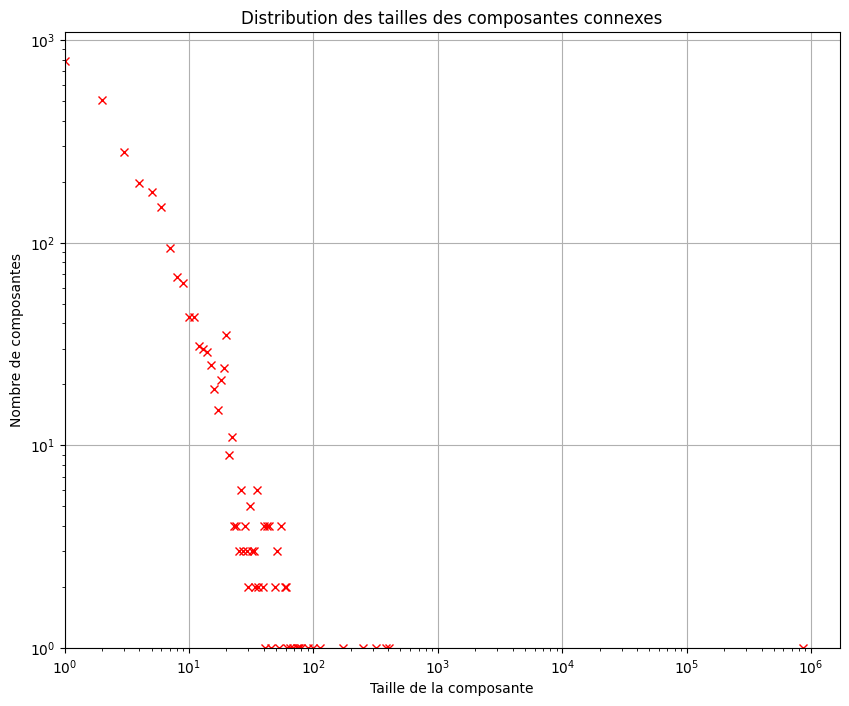

In [134]:
# Après avoir obtenu votre RDD de composantes connexes (comp_rdd)
# comp_rdd contient des paires (node_id, component_id)

# calculer la distribution des tailles
cc = comp_rdd.map(lambda x: (x[1], x[0]))  # (component_id, node_id)
cc = cc.groupByKey()  # Grouper par component_id
cc = cc.map(lambda x: (x[0], list(x[1])))  # (component_id, [node_ids])
cc = cc.map(lambda x: (len(x[1]), 1))  # (taille_composante, 1)
cc = cc.reduceByKey(lambda x, y: x + y)  # (taille_composante, count)

# collecter les données pour le plot
cc_stats = cc.collect()  # liste de tuples (taille, count)

# séparer les données pour X et Y
X = [size for size, count in cc_stats]  # tailles des composantes
Y = [count for size, count in cc_stats]  # nombre de composantes de chaque taille

plt.figure(figsize=(10, 8))
plt.plot(X, Y, 'rx')  # points rouges en forme de x

plt.xscale("log")
plt.xlabel("Taille de la composante")
plt.xlim(left=1)

plt.yscale("log")
plt.ylabel("Nombre de composantes")
plt.ylim(bottom=1)

plt.title('Distribution des tailles des composantes connexes')
plt.grid(True)
plt.show()

# DataFrame Standard

In [139]:
def charge_df(path):
    """Reçoit le chemin du fichier à charger et retourne un DF du dataset"""
    return spark.read.format("csv").option("header","false").load(path)

def nettoyer_df(df):
    """Reçoit un DF avec les données brutes et retourne un nouveau DF sans les en-têtes multilignes
    commençant par '#', et les colonnes séparées selon le séparateur tabulation
    Nettoyer les données brutes et les transformer en un DataFrame structuré avec deux colonnes entières k (source) et v (destination)"""
    # Obtenir le nom de la colonne unique créée lors du chargement
    # filtrage -> split:1ère colonne -> split:2ème colonne -> nettoyage -> Conversion en entier
    col_name = df.columns[0]
    return df.filter(f"{col_name} NOT LIKE '#%'")\
                .withColumn('k', split(df[col_name], '\t').getItem(0)) \
                .withColumn('v', split(df[col_name], '\t').getItem(1)) \
                .drop(col_name)\
                .withColumn("k",col("k").cast(IntegerType())) \
                .withColumn("v",col("v").cast(IntegerType())) 


def map_df(df):
    """Reçoit un DF avec 2 colonnes 'k', 'v' et retourne un nouveau DF résultant de la concaténation
    de l'DF d'entrée original et de lui-même où les colonnes étaient inversées 'k', 'v'
    Pour une arête (1, 2) en entrée, le résultat contiendra (1, 2) et (2, 1)"""
    return df.union(df.select(col("v").alias("k"), col("k").alias("v")))

def reduce_df(df):
    """Reçoit un DF déjà traité par map_df(), et pour chaque composant
    compte les nouvelles paires, retourne le DF"""
    global nb_nv_paire
    # regrouper par clé 'k' et agréger toutes les valeurs 'v' dans un Set:
    # créer une colonne 'min' contenant la valeur minimum entre 'k' et le min des 'v'
    # filtrer pour ne garder que les lignes où 'k' n'est pas déjà le minimum
    df = df.groupBy(col("k")).agg(collect_set("v").alias("v"))\
                                            .withColumn("min", least(col("k"), array_min("v")))\
                                            .filter((col("k")!=col('min')))

    # Calculer le nombre de nouvelles paires créées
    nb_nv_paire += df.withColumn("count", size("v")-1).select(sum("count")).collect()[0][0]

    # Préparer le DataFrame pour la prochaine itération:
    # exploser la liste valueList pour avoir une ligne par valeur
    # filtrer pour éviter les self-loops (min != valueList)
    # recréer les colonnes standard 'k' et 'v'
    return df.select(col("min").alias("a_min"), concat(array(col("k")), col("v")).alias("valueList"))\
                                                    .withColumn("valueList", explode("valueList"))\
                                                    .filter((col('a_min')!=col('valueList')))\
                                                    .select(col('a_min').alias("k"), col('valueList').alias("v")) 

def calc_cc_df(df):
    """Reçoit un DF prétraité et calcule CCF selon plusieurs jobs d'itérations de map/reduce_df, avec déduplication.
    Quand aucun nouveau pair n'est compté : retourne un DF avec les componentIDs de chaque groupe d'arêtes connectées"""
    nb_iteration = 0
    while True:
        nb_iteration += 1
        nb_pairs_start = nb_nv_paire.value

        df = map_df(df)
        df = reduce_df(df)
        df = df.distinct()

        print(f"Itération #{nb_iteration}: {nb_nv_paire.value} nouvelles paires")
        if nb_pairs_start == nb_nv_paire.value:
            print("\nPas de nouvelle paire, fin du calcul")
            break
    return df

# DataFrame tri secondaire

In [140]:
def nettoyer_df_sorted(df):
    """Reçoit un DF avec les données brutes et retourne un nouveau DF sans les en-têtes multilignes
    commençant par '#', et les colonnes séparées selon le séparateur tabulation"""
    col_name = df.columns[0]
    return df.filter(f"{col_name} NOT LIKE '#%'")\
                .withColumn('k', split(df[col_name], '\t').getItem(0)) \
                .withColumn('v', split(df[col_name], '\t').getItem(1)) \
                .drop(col_name)\
                .withColumn("k", col("k").cast(IntegerType())) \
                .withColumn("v", col("v").cast(IntegerType()))\
                .sort("k", "v")  # Tri

def map_df_sorted(df):
    """Reçoit un DF avec 2 colonnes 'k', 'v' et retourne un nouveau DF résultant de la concaténation
    de l'DF d'entrée original et de lui-même où les colonnes étaient inversées 'k', 'v' avec sorting"""
    inverted_df = df.select(col("v").alias("k"), col("k").alias("v")).sort("k", "v")
    return df.union(inverted_df).sort("k", "v")  # Tri 


def reduce_df_sorted(df):
    """Reçoit un DF déjà traité par iterate_map_df_sorted(), et pour chaque composant
    compte les nouvelles paires, le retour DF avec tri secondaire"""
    global nb_nv_paire

    # Réinitialiser l'accumulator pour cette itération
    previous_value = nb_nv_paire.value
    nb_nv_paire.value = 0

    # Définir la fenêtre pour le tri secondaire
    # Partitionner par la clé 'k' et trier les valeurs 'v' dans l'ordre croissant à l'intérieur de chaque partition
    window_spec = Window.partitionBy("k").orderBy("v")

    # Préparer les données pour le traitement partitionné
    # row_number: attribue un numéro de ligne à chaque valeur 'v' dans sa partition 'k' (triée).
    # first("v").over(window_spec) : pour chaque ligne, ajoute la première valeur (la plus petite) de la partition 'k'. C'est notre 'min_value'.
    # filtrer : ne garder que les lignes où ce 'min_value' est strictement inférieur à 'k'
    df_with_min = df.withColumn("row_num", row_number().over(window_spec))\
                   .withColumn("min_value", first("v").over(window_spec))\
                   .filter(col("min_value") < col("k"))

    # Compter les nouvelles paires et émettre (value, min_value)
    def process_partition(iterator):
        local_count = 0
        results = []

        # Parcourir chaque ligne de la partition
        for row in iterator:
            k, v, min_value = row['k'], row['v'], row['min_value']

            # Émettre (key, min_value)
            results.append((k, min_value))

            # Pour chaque valeur supplémentaire, incrémenter le compteur
            if v != min_value:
                local_count += 1
                # Émettre (value, min_value)
                results.append((v, min_value))

        nb_nv_paire.add(local_count)
        return results

    # Appliquer le traitement partition par partition
    result_rdd = df_with_min.rdd.mapPartitions(process_partition)

    # Créer le DataFrame résultant avec tri
    result_df = spark.createDataFrame(result_rdd, ["k", "v"]).distinct().sort("k", "v")

    return result_df

def calc_cc_df_sorted(df):
    """Reçoit un DF prétraité et calcule CCF avec tri secondaire selon
    plusieurs itérations de map_sorted/reduce_df_sorted, avec déduplication"""

    nb_iteration = 0
    previous_count = -1 # Variable pour suivre le compteur entre les itérations

    while True:
        nb_iteration += 1
        nb_pairs_start = nb_nv_paire.value # Sauvegarde de l'état du compteur

        # Map avec tri
        df = map_df_sorted(df)
        df = df.persist()
        map_count = df.count()

        # Reduce avec tri
        df = reduce_df_sorted(df)
        df = df.persist()
        reduce_count = df.count()

        # Déduplication
        df = df.distinct().sort("k", "v")
        df = df.persist()
        distinct_count = df.count()

        current_count = nb_nv_paire.value
        #print(f"Nombre de nouvelles paires pour l'itération #{nb_iteration}:\t{current_count}")
        print(f"Itération #{nb_iteration}: {current_count} nouvelles paires")
        # Nettoyage mémoire
        df.unpersist()
        spark.catalog.clearCache()

        # Condition d'arrêt: aucune nouvelle paire créée
        if current_count == 0 or current_count == previous_count:
            print("\nPas de nouvelle paire, fin du calcul")
            break

        previous_count = current_count # Mise à jour pour la prochaine itération

        # Sécurité pour éviter les boucles infinies
        if nb_iteration >= 15:
            print("\nNombre maximal d'itérations atteint(15)")
            break

        # Garbage collection manuel pour éviter heap size
        import gc
        gc.collect()

    return df

def count_connected_components(df):
    """Compte correctement le nombre de composantes connexes"""
    # Trouver le nœud racine (le leader) pour chaque nœud 'k'
    components = df.groupBy("k").agg(spark_min("v").alias("root"))
    # Compter les racines distinctes
    return components.select("root").distinct().count()

In [141]:
results_df = {
        'df_standard': [],
        'df_secondaire': []
    }

path = "/kaggle/input/webgoogle/web-Google.txt"
#path = "/kaggle/input/web-notredame/web-NotreDame.txt"

# DataFrame Standard
print("\nDataFrame Standard:")
df = charge_df(path)
df = nettoyer_df(df)
start = time.time()
comp_df = calc_cc_df(df)
print(f"Nombre de composantes connexes dans le graphique: {comp_df.select('k').distinct().count()}")
df_time = time.time() - start
results_df['df_standard'].append(df_time)
print(f"Temps: {df_time:.2f}s")


# DataFrame Tri Secondaire
print("\nDataFrame Tri Secondaire:")
df = charge_df(path)
df = nettoyer_df_sorted(df)
start = time.time()
comp_df_sorted = calc_cc_df_sorted(df)
num_components = count_connected_components(comp_df_sorted)
print(f"Nombre de composantes connexes dans le graphique: {num_components}")
df_sec_time = time.time() - start
results_df['df_secondaire'].append(df_sec_time)
print(f"Temps: {df_sec_time:.2f}s")


DataFrame Standard:


Itération #1: 142597157 nouvelles paires


Itération #2: 147355608 nouvelles paires


Itération #3: 150634380 nouvelles paires


Itération #4: 154522834 nouvelles paires


...

Itération #5: 2036207 nouvelles paires


Itération #6: 94252 nouvelles paires


Itération #7: 1395 nouvelles paires


Itération #8: 0 nouvelles paires

Pas de nouvelle paire, fin du calcul


Nombre de composantes connexes dans le graphique: 2746
Temps: 584.88s


In [142]:
results_df

{'df_standard': [537.2891192436218], 'df_secondaire': [584.8774347305298]}

In [143]:
results_final = {
    'rdd_standard': results['rdd_standard'],
    'rdd_secondaire': results['rdd_secondaire'],
    'df_standard': results_df['df_standard'],
    'df_secondaire': results_df['df_secondaire']
}
results_final

{'rdd_standard': [1747.5408234596252],
 'rdd_secondaire': [1781.4719104766846],
 'df_standard': [537.2891192436218],
 'df_secondaire': [584.8774347305298]}

In [144]:
# Extraire les valeurs des listes et créer un dictionnaire avec les temps
times = {method: values[0] for method, values in results_final.items()}

# Trier les méthodes par temps croissant
sorted_results = sorted(times.items(), key=lambda x: x[1])

print("=== COMPARAISON DES PERFORMANCES ===")
print("Classement (du plus rapide au plus lent):")
print("-" * 50)

for i, (method, time_sec) in enumerate(sorted_results, 1):
    time_min = time_sec / 60
    print(f"{i}. {method.upper():<15}: {time_sec:>7.2f}s ({time_min:>6.2f}min)")

print("-" * 50)

# Analyse comparative
fastest_method, fastest_time = sorted_results[0]
slowest_method, slowest_time = sorted_results[-1]
improvement_ratio = slowest_time / fastest_time

print(f"✓ Meilleure méthode: {fastest_method} ({fastest_time:.2f}s)")
print(f"✓ Ratio d'amélioration: {improvement_ratio:.2f}x plus rapide")
print(f"✓ Économie de temps: {slowest_time - fastest_time:.2f}s")

=== COMPARAISON DES PERFORMANCES ===
Classement (du plus rapide au plus lent):
--------------------------------------------------
1. DF_STANDARD    :  537.29s (  8.95min)
2. DF_SECONDAIRE  :  584.88s (  9.75min)
3. RDD_STANDARD   : 1747.54s ( 29.13min)
4. RDD_SECONDAIRE : 1781.47s ( 29.69min)
--------------------------------------------------
✓ Meilleure méthode: df_standard (537.29s)
✓ Ratio d'amélioration: 3.32x plus rapide
✓ Économie de temps: 1244.18s


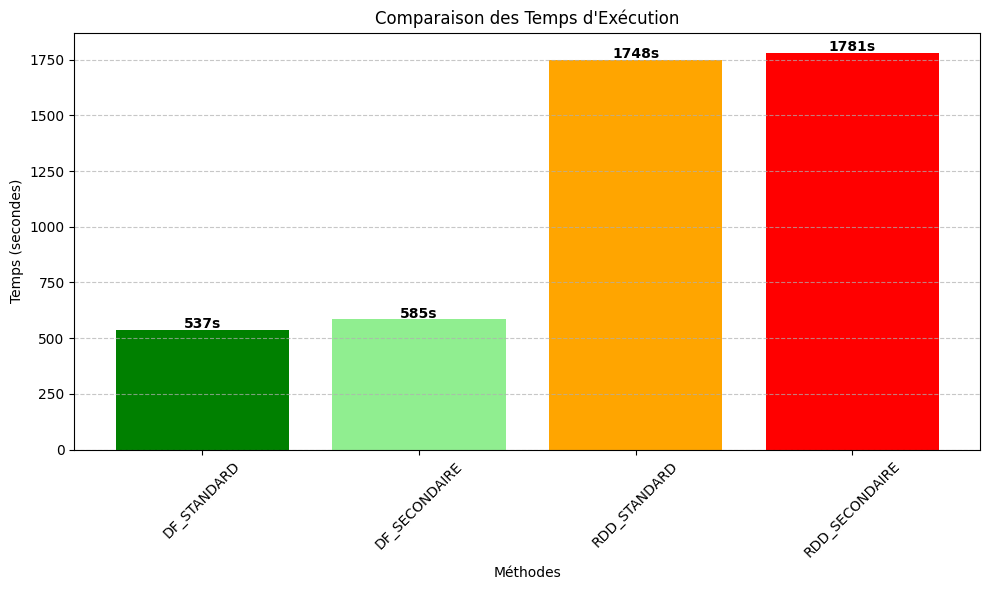

In [145]:
methods = [m.upper() for m, _ in sorted_results]
times = [t for _, t in sorted_results]

plt.figure(figsize=(10, 6))
plt.bar(methods, times, color=['green', 'lightgreen', 'orange', 'red'])
plt.title('Comparaison des Temps d\'Exécution')
plt.ylabel('Temps (secondes)')
plt.xlabel('Méthodes')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for i, v in enumerate(times):
    plt.text(i, v + 8, f'{v:.0f}s', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()